In [2]:
###############
# Directories #
###############
directory = 'C:\\Users\\20234503\\Desktop\\Research\\Weather and Strikes\\Project\\' 
##########
#Packages#
##########
import re
import json
import pandas as pd

import numpy as np
from itertools import product
import matplotlib.pyplot as plt
from collections import Counter
import string

import geopandas as gpd
from shapely.ops import unary_union

from shapely.geometry import Point
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.patches as mpatches
from matplotlib.patches import Patch

# --- keep this near your imports ---
import types
import inspect
import sys

def clear_env(keep=None):
    """
    Delete user-defined globals while keeping:
      - all imported modules (e.g. pd, np, gpd, plt, string, etc.)
      - functions/classes imported via `from ... import ...` (e.g. unary_union, Counter, Patch)
      - anything explicitly listed in `keep`
      - underscore-prefixed names and this function itself
    """
    if keep is None:
        keep = []
    keep = set(keep) | {"clear_env"}

    g = globals()
    for name, val in list(g.items()):
        # never touch dunders, explicit keepers, or this function
        if name.startswith("_") or name in keep:
            continue

        # keep modules (e.g., pd, np, gpd, plt, string, re, json, sys, types, etc.)
        if isinstance(val, types.ModuleType):
            continue

        # keep imported functions/classes (e.g., unary_union, Counter, Patch, product)
        # (callables or types) whose defining module is not __main__
        if (callable(val) or isinstance(val, type)):
            mod = inspect.getmodule(val)
            if mod is not None and mod.__name__ != "__main__":
                continue

        # otherwise, remove it (likely user-created data/vars/objects)
        try:
            del g[name]
        except Exception:
            pass

# Checked if code is correct 13/11/2025 

In [4]:
################################
# Extracting Labour Stike data #
################################
file = directory + 'Data\\Raw\\Labour Conflict\\Labour Action Tracker.js'
# (1) Open and read the JavaScript file
with open(file, 'r') as file:
    js_content = file.read()

# (2) Extract JSON components using regular expressions
# Assuming JSON components are enclosed by `{ }`
json_matches = re.findall(r'\{[^}]+\}', js_content)

# (3) Parse each JSON component and store them in a list
parsed_json_objects = []

for json_str in json_matches:
    try:
        # Parse JSON string into a Python dictionary
        parsed_json = json.loads(json_str)
        parsed_json_objects.append(parsed_json)
    except json.JSONDecodeError as e:
        print(f"Error parsing JSON: {e}")


# (4) Create a Pandas DataFrame from the list of dictionaries
if parsed_json_objects:
    df = pd.DataFrame(parsed_json_objects)

 # Save to a CSV file
    df.to_csv(directory + 'Data\\labour_action_tracker.csv', index=False)

print("Data extraction and CSV creation completed successfully.")

clear_env(keep=["directory", "unary_union"])

# Checked if code is correct 13/11/2025 

Data extraction and CSV creation completed successfully.


In [6]:
###################################################
# Cleaning & Manlipuation of Labour Conflict Data #
###################################################

lconflict_event = pd.read_csv(directory + 'Data\\labour_action_tracker.csv')

lconflict_event = lconflict_event.replace(r'^\s*$', pd.NA, regex=True) # Replace blank (empty string) values with missing (NaN) in the DataFrame

n_missing = lconflict_event['Employer'].isna().sum()
print(f"Number of missing observations in Employer: {n_missing}")
lconflict_event = lconflict_event.dropna(subset=['Employer']).reset_index(drop=True) #Dropping rows with missing Employer values

lconflict_event['UniqueID'] = range(len(lconflict_event))

clear_env(keep=["directory", "unary_union", "lconflict_event"])

Number of missing observations in Employer: 243


In [7]:
############################################
# Compute % missing for selected variables #
############################################
missing_perc = {
    "Employer": lconflict_event['Employer'].isna().mean() * 100,
    "Labor Organization": lconflict_event['Labor Organization'].isna().mean() * 100,
    "Industry": lconflict_event['Industry'].isna().mean() * 100,
    "Bargaining Unit Size": lconflict_event['Bargaining Unit Size'].isna().mean() * 100,
    "Approximate Number of Participants": lconflict_event['Approximate Number of Participants'].isna().mean() * 100,
    "Start Date": lconflict_event['Start Date'].isna().mean() * 100,
    "End Date": lconflict_event['End Date'].isna().mean() * 100,
    "Strike or Protest": lconflict_event['Strike or Protest'].isna().mean() * 100,
    "Worker Demands": lconflict_event['Worker Demands'].isna().mean() * 100
}

# Create summary DataFrame, rounded to 1 decimal
missing_data_summary = (
    pd.DataFrame(list(missing_perc.items()), columns=["Variable", "% Missing"])
    .assign(**{"% Missing": lambda x: x["% Missing"].round(1)})
    .sort_values("% Missing", ascending=False)
    .reset_index(drop=True)
)

outpath = directory + "Results_2\\missing_data_summary.tex"

# Make a copy so we don't overwrite the numeric version
latex_df = missing_data_summary.copy()

# Format "% Missing" as string with one decimal + percent sign
latex_df["% Missing"] = latex_df["% Missing"].map(lambda x: f"{x:.1f}\\%")

# Export to LaTeX
latex_df.to_latex(
    outpath,
    index=False,
    caption="Percentage of Missing Observations by Variable",
    label="tab:missing_data",
    column_format="l r",
    escape=False  # important so LaTeX sees "\%" as percent sign
)

print(f"LaTeX table with % signs saved to: {outpath}")

clear_env(keep=["directory", "unary_union", "lconflict_event"])
# Checked if code is correct 08/09/2024

LaTeX table with % signs saved to: C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2\missing_data_summary.tex


In [8]:
#####################
# Outcome Variables #
#####################

In [9]:
#####################
# (a) - Action Type #
#####################
missing_percent = lconflict_event['Strike or Protest'].isna().mean() * 100
print(f"% of missing data in 'Strike or Protest': {missing_percent:.2f}%")

lconflict_event['Strike'] = (lconflict_event['Strike or Protest'] == 'Strike').astype(int)
lconflict_event['Protest'] = (lconflict_event['Strike or Protest'] == 'Protest').astype(int)
lconflict_event['Labour_unrest'] = ((lconflict_event['Strike or Protest'] == 'Protest') |  (lconflict_event['Strike or Protest'] == 'Strike')).astype(int)

clear_env(keep=["directory", "unary_union", "lconflict_event"])
# Checked if code is correct 08/09/2024

% of missing data in 'Strike or Protest': 0.00%


In [10]:
########################################################
# Creation of Single and Multi-location Events Dataset #
########################################################
lconflict_event_sl = lconflict_event[lconflict_event['Number of Locations'] <= 1]
lconflict_event_ml = lconflict_event[lconflict_event['Number of Locations'] > 1]

# Columns with spatial data 
spatial_columns = ['Address', 'City', 'State', 'Zip Code', 'Latitude, Longitude'] 

for col in spatial_columns:
    lconflict_event_ml[col] = lconflict_event_ml[col].fillna("").astype(str)
# Missing 'Latitude, Longitude' data for two events with multiple locations, but all other spatcial information is provided. These observations are droped from our analysis

# Split spatial columns on ';' and create lists for col in spatial_columns:
for col in spatial_columns: 
    lconflict_event_ml[col] = lconflict_event_ml[col].str.split(';') 

# Pad shorter lists in each row to match the maximum length
def pad_row(row, spatial_cols):
    # Determine the maximum length for this row
    max_len = max(len(row[col]) for col in spatial_cols)
    # Pad each column to the maximum length
    for col in spatial_cols:
        row[col] = row[col] + [np.nan] * (max_len - len(row[col]))
    return row

# Apply padding to all rows, ensures that for citys' with inconsistent number of adressses all have the same lenght
lconflict_event_ml = lconflict_event_ml.apply(lambda row: pad_row(row, spatial_columns), axis=1)

# Explode the spatial columns to separate rows 
lconflict_event_ml = lconflict_event_ml.explode(spatial_columns, ignore_index=True)

# Drop rows where any spatial column has missing or invalid data
lconflict_event_ml = lconflict_event_ml.dropna(subset=spatial_columns)  # Drop rows with NaN
lconflict_event_ml = lconflict_event_ml[~lconflict_event_ml[spatial_columns].isin([""]).any(axis=1)]  # Drop rows with empty strings
lconflict_event_all = pd.concat([lconflict_event_ml, lconflict_event_sl], ignore_index=True)

# Generate labels beyond A-Z (AA, AB, ..., AZ, BA, etc.)
letters = list(string.ascii_uppercase)
extended_labels = letters + [''.join(p) for p in product(letters, repeat=3)]  # Extends beyond "Z"

# Ensure there are enough labels
max_events = lconflict_event_all.groupby('UniqueID').size().max()
if len(extended_labels) < max_events:
    extended_labels += [''.join(p) for p in product(letters, repeat=3)]  # Extend further if needed

# Assign labels based on event order within each 'positionId'
lconflict_event_all['UniqueID'] = lconflict_event_all['UniqueID'].astype(int)
lconflict_event_all['Multiple_event_ID'] = (
    lconflict_event_all.groupby('UniqueID').cumcount().apply(lambda x: extended_labels[x])
)

lconflict_event_all['Event_ID'] = lconflict_event_all['UniqueID'].astype(str) + lconflict_event_all['Multiple_event_ID'].astype(str)

lconflict_event_all.to_csv(directory + 'Data\\lconflict_event_all.csv', index=False)
lconflict_event_sl.to_csv(directory + 'Data\\lconflict_event_sl.csv', index=False)

clear_env(keep=["directory", "unary_union", "lconflict_event", "lconflict_event_all", "lconflict_event_ml", "lconflict_event_sl"])
# Checked if code is correct 13/11/2025


C:\Users\20234503\AppData\Local\Temp\ipykernel_21780\326723304.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lconflict_event_ml[col] = lconflict_event_ml[col].fillna("").astype(str)
C:\Users\20234503\AppData\Local\Temp\ipykernel_21780\326723304.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lconflict_event_ml[col] = lconflict_event_ml[col].fillna("").astype(str)
C:\Users\20234503\AppData\Local\Temp\ipykernel_21780\326723304.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy o

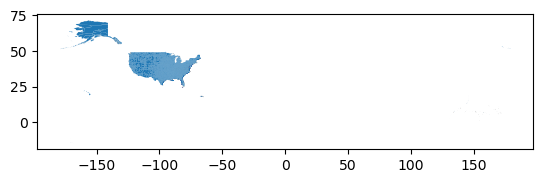

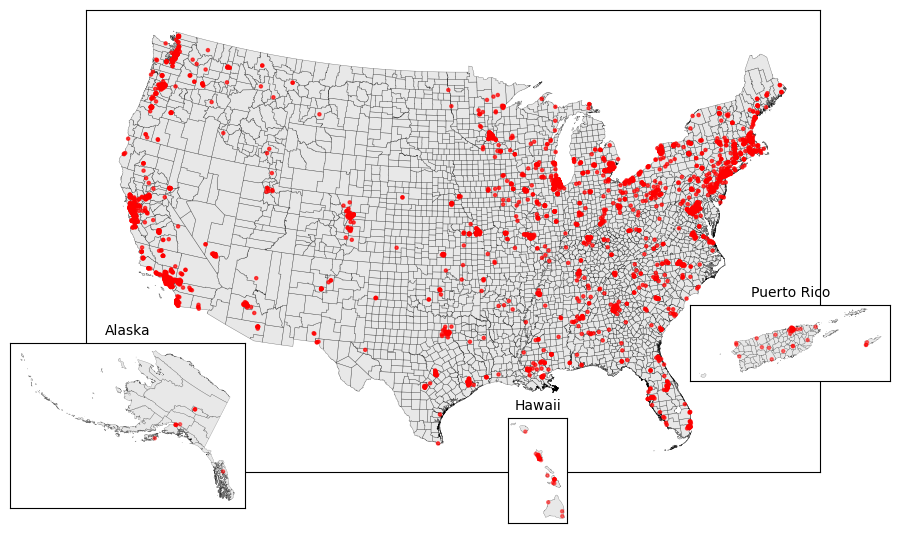

In [ ]:
###################################################
# Creation of County-Day Panel of Labour Conflict # (Multi-Location Dataset)
###################################################

# (1) U.S. County Map
US_county_shp = gpd.read_file(directory+'Data\\Raw\\US Counties\\US_County_SHP\\c_05mr24.shp')
US_county_shp.plot()
plt.show()

US_county_shp = (
    US_county_shp.groupby('FIPS')
    .agg({
        'STATE': 'first',
        'CWA': 'first',
        'COUNTYNAME': 'first',
        'TIME_ZONE': 'first',
        'FE_AREA': 'first',
        'LON': 'mean',
        'LAT': 'mean',
        'geometry': lambda x: unary_union(list(x))
    })
    .reset_index()
)
State = US_county_shp[["FIPS", "STATE"]]

US_county_shp = gpd.GeoDataFrame(US_county_shp, geometry='geometry', crs="EPSG:4326")

# (2) U.S. County Map & Location of Labour Unrest Events
event_points = lconflict_event_all[['Labour_unrest', 'Multiple_event_ID', 'Event_ID', 'Latitude, Longitude']]
event_points = event_points[~event_points['Latitude, Longitude'].str.contains(';')] # Removes observations for which we do have multiple lat and long locations
event_points[['Latitude', 'Longitude']] = event_points['Latitude, Longitude'].str.split(', ', expand=True)

# Convert to GeoDataFrame
geometry = [Point(xy) for xy in zip(event_points["Longitude"], event_points["Latitude"])]
event_gdf = gpd.GeoDataFrame(event_points, geometry=geometry, crs="EPSG:4326")

# Reproject to EPSG:5070
event_gdf = event_gdf.to_crs("EPSG:5070")
US_county_shp = US_county_shp.to_crs("EPSG:5070")

# Define geographic bounding boxes for different regions (EPSG:5070) #Use GIS to identify the correct bounding boxes!
contiguous_bounds = [-2453691.2025, 171085.9341, 2365756.5659, 3381509.2103]
alaska_bounds = [-5624079.5091, 3906729.8828, -2123879.3102, 6507096.4794]
hawaii_bounds = [-6338989.6804, 1498912.4257, -5921482.1404, 2141378.3664]
puerto_rico_bounds = [3026333.5643, -81515.6598, 3411431.8432, 76241.1847]

# Separate the regions based on bounding boxes
contiguous = US_county_shp.cx[contiguous_bounds[0]:contiguous_bounds[2],contiguous_bounds[1]:contiguous_bounds[3]]
alaska = US_county_shp.cx[alaska_bounds[0]:alaska_bounds[2], alaska_bounds[1]:alaska_bounds[3]]
hawaii = US_county_shp.cx[hawaii_bounds[0]:hawaii_bounds[2], hawaii_bounds[1]:hawaii_bounds[3]]
puerto_rico = US_county_shp.cx[puerto_rico_bounds[0]:puerto_rico_bounds[2], puerto_rico_bounds[1]:puerto_rico_bounds[3]]

# Separate regions
contiguous_event = event_gdf.cx[contiguous_bounds[0]:contiguous_bounds[2], contiguous_bounds[1]:contiguous_bounds[3]]
alaska_events = event_gdf.cx[alaska_bounds[0]:alaska_bounds[2], alaska_bounds[1]:alaska_bounds[3]]
hawaii_events = event_gdf.cx[hawaii_bounds[0]:hawaii_bounds[2], hawaii_bounds[1]:hawaii_bounds[3]]
puerto_rico_events = event_gdf.cx[puerto_rico_bounds[0]:puerto_rico_bounds[2], puerto_rico_bounds[1]:puerto_rico_bounds[3]]

# Define colors for strike and non-strike events
event_colors = {0: 'blue', 1: 'red'}  # Non-strike (0) = blue, Strike (1) = red

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot base map
contiguous.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.3, alpha=0.5)

# Plot event points with colors based on strike variable
contiguous_event.plot(
    ax=ax, 
    markersize=5, 
    alpha=0.7,
    color=contiguous_event['Labour_unrest'].map(event_colors),
    legend=True,
)

# ---- Alaska inset (Bottom Right) ----
ax_inset_alaska = fig.add_axes([0.05, 0.05, 0.275, 0.275])  
alaska.plot(ax=ax_inset_alaska, color='lightgray', edgecolor='black', linewidth=0.2, alpha=0.5)
alaska_events.plot(
    ax=ax_inset_alaska, 
    markersize=5, 
    alpha=0.5,
    color=alaska_events['Labour_unrest'].map(event_colors)
)
ax_inset_alaska.set_xticks([])
ax_inset_alaska.set_yticks([])
ax_inset_alaska.set_title("Alaska", fontsize=10)

# ---- Hawaii inset (Bottom Middle) ----
ax_inset_hawaii = fig.add_axes([0.51, 0.025, 0.175, 0.175])
hawaii.plot(ax=ax_inset_hawaii, color='lightgray', edgecolor='black', linewidth=0.2, alpha=0.5)
hawaii_events.plot(
    ax=ax_inset_hawaii, 
    markersize=5, 
    alpha=0.5,
    color=hawaii_events['Labour_unrest'].map(event_colors)
)
ax_inset_hawaii.set_xticks([])
ax_inset_hawaii.set_yticks([])
ax_inset_hawaii.set_title("Hawaii", fontsize=10)

# ---- Puerto Rico inset (Bottom Left) ----
ax_inset_puerto_rico = fig.add_axes([0.75, 0.225, 0.2, 0.2])
puerto_rico.plot(ax=ax_inset_puerto_rico, color='lightgray', edgecolor='black', linewidth=0.2, alpha=0.5)
puerto_rico_events.plot(
    ax=ax_inset_puerto_rico, 
    markersize=5, 
    alpha=0.5,
    color=puerto_rico_events['Labour_unrest'].map(event_colors)
)
ax_inset_puerto_rico.set_xticks([])
ax_inset_puerto_rico.set_yticks([])
ax_inset_puerto_rico.set_title("Puerto Rico", fontsize=10)

# Final touches
ax.set_xticks([])
ax.set_yticks([])

plt.show()

# (3) Assigning Labour Unrest Events to Counties
valid_coords = lconflict_event_all['Latitude, Longitude'].str.strip().str.contains(r'^-?\d+\.?\d*,\s*-?\d+\.?\d*$') # Remove leading/trailing spaces and check for valid format (a single comma, two float parts)

# Separate clean and malformed rows
clean_events = lconflict_event_all[valid_coords].copy()
bad_events = lconflict_event_all[~valid_coords].copy()

# Split the valid ones into float columns
clean_events[['latitude', 'longitude']] = clean_events['Latitude, Longitude'] \
    .str.split(',', expand=True) \
    .apply(lambda col: col.str.strip().astype(float))


events_gdf = gpd.GeoDataFrame(
    clean_events,
    geometry=gpd.points_from_xy(clean_events.longitude, clean_events.latitude),
    crs="EPSG:4326"  # WGS84
)

events_gdf = events_gdf.to_crs(epsg=5070)
US_county_shp = US_county_shp.to_crs(events_gdf.crs)

#Matching
matched = gpd.sjoin(events_gdf, US_county_shp, how='left', predicate='within')
unmatched = matched[matched['index_right'].isna()]

#County Panel of Labour Unrest
matched['date'] = pd.to_datetime(matched['Start Date'])
matched['month'] = matched['date'].dt.month
matched['year'] = matched['date'].dt.year

#'FIPS', 'month', 'year'
unrest_county_D_subset = matched.groupby(['FIPS', 'date']).agg({
    'Strike': 'sum',      # Sum event counts if you have an event count column
    'Protest': 'sum',
    'Labour_unrest': 'sum',

}).reset_index()


# Adding County Days with No Labour Unrest
lconflict_event_all['date'] = pd.to_datetime(lconflict_event_all['Start Date'])
start_date = lconflict_event_all['date'].min() #.replace(day=1)
end_date = lconflict_event_all['date'].max() #.replace(day=1)
all_days = pd.date_range(start=start_date, end=end_date, freq='D')

# Select relevant columns (adjust based on available columns)
county_df = US_county_shp[["FIPS"]].copy()
#county_df = county_df.drop_duplicates(subset=['county_state'], keep='first')

#Merging with temporal data
all_combinations = pd.MultiIndex.from_product([county_df['FIPS'], all_days], names=['FIPS', 'date']).to_frame(index=False)
unrest_county_D = pd.merge(unrest_county_D_subset, all_combinations, on=['FIPS', 'date'], how='right') # how='right' creates a dataset of all counties

unrest_county_D['Strike'] = unrest_county_D['Strike'].fillna(0)
unrest_county_D['Protest'] = unrest_county_D['Protest'].fillna(0)
unrest_county_D['Labour_unrest'] = unrest_county_D['Labour_unrest'].fillna(0)


# Create a date range for the entire period of interest
# Efficiently create 'at least one event' column using merge indicator
event_keys = unrest_county_D_subset[['FIPS']].drop_duplicates()
event_keys['at least one event'] = 1

unrest_county_D = unrest_county_D.merge(
    event_keys, on=['FIPS'], how='left'
)

unrest_county_D['at least one event'] = unrest_county_D['at least one event'].fillna(0).astype(int)

unrest_county_D = unrest_county_D.merge(
    State, on=['FIPS'], how='left'
)

# Save the final DataFrame to a CSV file
unrest_county_D.to_csv(directory + 'Data\\labour_unrest_county_day_panel.csv', index=False)

clear_env(keep=["directory", "unary_union", "lconflict_event", "lconflict_event_all", "lconflict_event_ml", "lconflict_event_sl", "matched", "unmatched", "bad_events", "unrest_county_D"])
# Checked if code is correct 08/09/2024

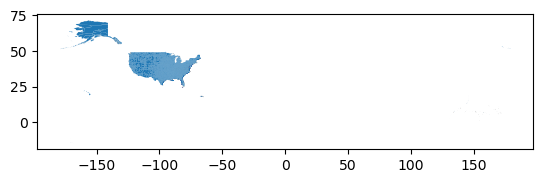

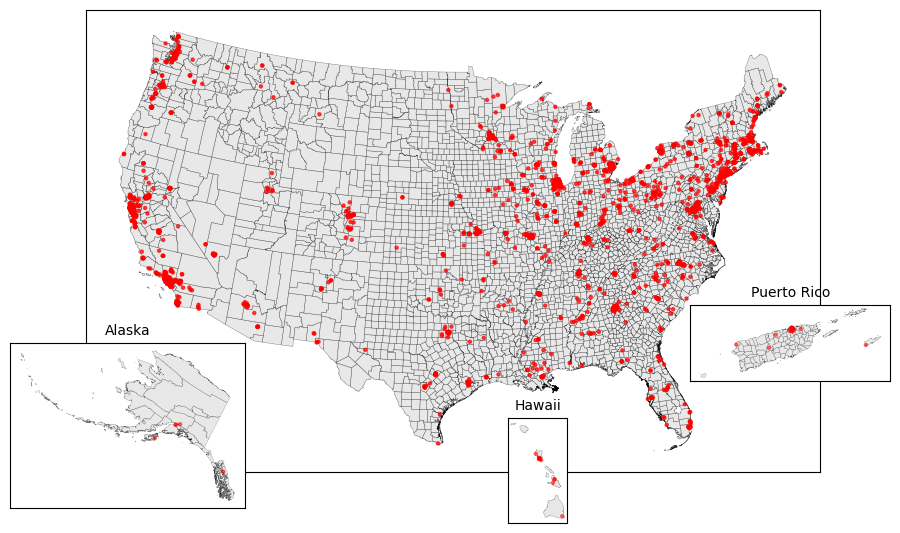

C:\Users\20234503\AppData\Local\Temp\ipykernel_21780\1942103893.py:163: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lconflict_event_sl['date'] = pd.to_datetime(lconflict_event_sl['Start Date'])


In [17]:
###################################################
# Creation of County-Day Panel of Labour Conflict # (Single-Location Dataset)
###################################################

# (1) U.S. County Map
US_county_shp = gpd.read_file(directory+'Data\\Raw\\US Counties\\US_County_SHP\\c_05mr24.shp')
US_county_shp.plot()
plt.show()

US_county_shp = (
    US_county_shp.groupby('FIPS')
    .agg({
        'STATE': 'first',
        'CWA': 'first',
        'COUNTYNAME': 'first',
        'TIME_ZONE': 'first',
        'FE_AREA': 'first',
        'LON': 'mean',
        'LAT': 'mean',
        'geometry': lambda x: unary_union(list(x))
    })
    .reset_index()
)
State = US_county_shp[["FIPS", "STATE"]]

US_county_shp = gpd.GeoDataFrame(US_county_shp, geometry='geometry', crs="EPSG:4326")

# (2) U.S. County Map & Location of Labour Unrest Events
event_points = lconflict_event_sl[['Labour_unrest', 'Latitude, Longitude']]
event_points = event_points[~event_points['Latitude, Longitude'].str.contains(';')] # Removes observations for which we do have multiple lat and long locations
event_points[['Latitude', 'Longitude']] = event_points['Latitude, Longitude'].str.split(', ', expand=True)

# Convert to GeoDataFrame
geometry = [Point(xy) for xy in zip(event_points["Longitude"], event_points["Latitude"])]
event_gdf = gpd.GeoDataFrame(event_points, geometry=geometry, crs="EPSG:4326")

# Reproject to EPSG:5070
event_gdf = event_gdf.to_crs("EPSG:5070")
US_county_shp = US_county_shp.to_crs("EPSG:5070")

# Define geographic bounding boxes for different regions (EPSG:5070) #Use GIS to identify the correct bounding boxes!
contiguous_bounds = [-2453691.2025, 171085.9341, 2365756.5659, 3381509.2103]
alaska_bounds = [-5624079.5091, 3906729.8828, -2123879.3102, 6507096.4794]
hawaii_bounds = [-6338989.6804, 1498912.4257, -5921482.1404, 2141378.3664]
puerto_rico_bounds = [3026333.5643, -81515.6598, 3411431.8432, 76241.1847]

# Separate the regions based on bounding boxes
contiguous = US_county_shp.cx[contiguous_bounds[0]:contiguous_bounds[2],contiguous_bounds[1]:contiguous_bounds[3]]
alaska = US_county_shp.cx[alaska_bounds[0]:alaska_bounds[2], alaska_bounds[1]:alaska_bounds[3]]
hawaii = US_county_shp.cx[hawaii_bounds[0]:hawaii_bounds[2], hawaii_bounds[1]:hawaii_bounds[3]]
puerto_rico = US_county_shp.cx[puerto_rico_bounds[0]:puerto_rico_bounds[2], puerto_rico_bounds[1]:puerto_rico_bounds[3]]

# Separate regions
contiguous_event = event_gdf.cx[contiguous_bounds[0]:contiguous_bounds[2], contiguous_bounds[1]:contiguous_bounds[3]]
alaska_events = event_gdf.cx[alaska_bounds[0]:alaska_bounds[2], alaska_bounds[1]:alaska_bounds[3]]
hawaii_events = event_gdf.cx[hawaii_bounds[0]:hawaii_bounds[2], hawaii_bounds[1]:hawaii_bounds[3]]
puerto_rico_events = event_gdf.cx[puerto_rico_bounds[0]:puerto_rico_bounds[2], puerto_rico_bounds[1]:puerto_rico_bounds[3]]

# Define colors for strike and non-strike events
event_colors = {0: 'blue', 1: 'red'}  # Non-strike (0) = blue, Strike (1) = red

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot base map
contiguous.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.3, alpha=0.5)

# Plot event points with colors based on strike variable
contiguous_event.plot(
    ax=ax, 
    markersize=5, 
    alpha=0.7,
    color=contiguous_event['Labour_unrest'].map(event_colors),
    legend=True,
)

# ---- Alaska inset (Bottom Right) ----
ax_inset_alaska = fig.add_axes([0.05, 0.05, 0.275, 0.275])  
alaska.plot(ax=ax_inset_alaska, color='lightgray', edgecolor='black', linewidth=0.2, alpha=0.5)
alaska_events.plot(
    ax=ax_inset_alaska, 
    markersize=5, 
    alpha=0.5,
    color=alaska_events['Labour_unrest'].map(event_colors)
)
ax_inset_alaska.set_xticks([])
ax_inset_alaska.set_yticks([])
ax_inset_alaska.set_title("Alaska", fontsize=10)

# ---- Hawaii inset (Bottom Middle) ----
ax_inset_hawaii = fig.add_axes([0.51, 0.025, 0.175, 0.175])
hawaii.plot(ax=ax_inset_hawaii, color='lightgray', edgecolor='black', linewidth=0.2, alpha=0.5)
hawaii_events.plot(
    ax=ax_inset_hawaii, 
    markersize=5, 
    alpha=0.5,
    color=hawaii_events['Labour_unrest'].map(event_colors)
)
ax_inset_hawaii.set_xticks([])
ax_inset_hawaii.set_yticks([])
ax_inset_hawaii.set_title("Hawaii", fontsize=10)

# ---- Puerto Rico inset (Bottom Left) ----
ax_inset_puerto_rico = fig.add_axes([0.75, 0.225, 0.2, 0.2])
puerto_rico.plot(ax=ax_inset_puerto_rico, color='lightgray', edgecolor='black', linewidth=0.2, alpha=0.5)
puerto_rico_events.plot(
    ax=ax_inset_puerto_rico, 
    markersize=5, 
    alpha=0.5,
    color=puerto_rico_events['Labour_unrest'].map(event_colors)
)
ax_inset_puerto_rico.set_xticks([])
ax_inset_puerto_rico.set_yticks([])
ax_inset_puerto_rico.set_title("Puerto Rico", fontsize=10)

# Final touches
ax.set_xticks([])
ax.set_yticks([])

plt.show()

# (3) Assigning Labour Unrest Events to Counties
valid_coords = lconflict_event_sl['Latitude, Longitude'].str.strip().str.contains(r'^-?\d+\.?\d*,\s*-?\d+\.?\d*$') # Remove leading/trailing spaces and check for valid format (a single comma, two float parts)

# Separate clean and malformed rows
clean_events = lconflict_event_sl[valid_coords].copy()
bad_events = lconflict_event_sl[~valid_coords].copy()

# Split the valid ones into float columns
clean_events[['latitude', 'longitude']] = clean_events['Latitude, Longitude'] \
    .str.split(',', expand=True) \
    .apply(lambda col: col.str.strip().astype(float))


events_gdf = gpd.GeoDataFrame(
    clean_events,
    geometry=gpd.points_from_xy(clean_events.longitude, clean_events.latitude),
    crs="EPSG:4326"  # WGS84
)

events_gdf = events_gdf.to_crs(epsg=5070)
US_county_shp = US_county_shp.to_crs(events_gdf.crs)

#Matching
matched = gpd.sjoin(events_gdf, US_county_shp, how='left', predicate='within')
unmatched = matched[matched['index_right'].isna()]

#County Panel of Labour Unrest
matched['date'] = pd.to_datetime(matched['Start Date'])
matched['month'] = matched['date'].dt.month
matched['year'] = matched['date'].dt.year

#'FIPS', 'month', 'year'
unrest_county_D_subset_sl = matched.groupby(['FIPS', 'date']).agg({
    'Strike': 'sum',      # Sum event counts if you have an event count column
    'Protest': 'sum',
    'Labour_unrest': 'sum',

}).reset_index()


# Adding County Days with No Labour Unrest
lconflict_event_sl['date'] = pd.to_datetime(lconflict_event_sl['Start Date'])
start_date = lconflict_event_sl['date'].min() #.replace(day=1)
end_date = lconflict_event_sl['date'].max() #.replace(day=1)
all_days = pd.date_range(start=start_date, end=end_date, freq='D')

# Select relevant columns (adjust based on available columns)
county_df = US_county_shp[["FIPS"]].copy()
#county_df = county_df.drop_duplicates(subset=['county_state'], keep='first')

#Merging with temporal data
all_combinations = pd.MultiIndex.from_product([county_df['FIPS'], all_days], names=['FIPS', 'date']).to_frame(index=False)
unrest_county_D_sl = pd.merge(unrest_county_D_subset_sl, all_combinations, on=['FIPS', 'date'], how='right') # how='right' creates a dataset of all counties

unrest_county_D_sl['Strike'] = unrest_county_D_sl['Strike'].fillna(0)
unrest_county_D_sl['Protest'] = unrest_county_D_sl['Protest'].fillna(0)
unrest_county_D_sl['Labour_unrest'] = unrest_county_D_sl['Labour_unrest'].fillna(0)


# Create a date range for the entire period of interest
# Efficiently create 'at least one event' column using merge indicator
event_keys = unrest_county_D_subset_sl[['FIPS']].drop_duplicates()
event_keys['at least one event'] = 1

unrest_county_D_sl = unrest_county_D_sl.merge(
    event_keys, on=['FIPS'], how='left'
)

unrest_county_D_sl['at least one event'] = unrest_county_D_sl['at least one event'].fillna(0).astype(int)

unrest_county_D_sl = unrest_county_D_sl.merge(
    State, on=['FIPS'], how='left'
)

# Save the final DataFrame to a CSV file
unrest_county_D_sl.to_csv(directory + 'Data\\labour_unrest_county_day_panel_sl.csv', index=False)

clear_env(keep=["directory", "unary_union", "lconflict_event", "lconflict_event_all", "lconflict_event_ml", "lconflict_event_sl", "matched", "unmatched", "bad_events", "unrest_county_D", "unrest_county_D_sl"])
# Checked if code is correct 08/09/2024